In [ ]:
#install a foolbox module
!pip install foolbox


Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 1.7 MB 32.9 MB/s 
     |████████████████████████████████| 182 kB 70.0 MB/s 
     |████████████████████████████████| 62 kB 1.7 MB/s 
     |████████████████████████████████| 63 kB 1.8 MB/s 
  Attempting uninstall: requests
    Found existing installation: requests 2.23.0
    Uninstalling requests-2.23.0:
      Successfully uninstalled requests-2.23.0


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.vgg19 import preprocess_input, decode_predictions
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
model = tf.keras.applications.VGG19(weights="imagenet")

574710816/574710816 [==============================] - 5s 0us/step


1/1 [==============================] - 1s 1s/step


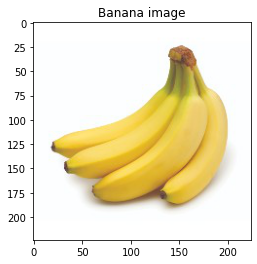

35363/35363 [==============================] - 0s 0us/step
Predicted: [('n07753592', 'banana', 0.99046373), ('n07749582', 'lemon', 0.0012841888), ('n07716358', 'zucchini', 0.00096554286)]


In [ ]:
img_path = '/content/drive/MyDrive/master 3rd s/Методы распознавания образов/Copy of banana_origin_224.jpg'
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

preds = model.predict(x)
plt.figure()
plt.imshow(img)
plt.title('Banana image')
plt.show()
print('Predicted:', decode_predictions(preds, top=3)[0])

LinfFastGradientAttack,L2ClippingAwareAdditiveUniformNoiseAttack,SaltAndPepperNoiseAttack,L2DeepFoolAttack, LinfDeepFoolAttack,GaussianBlurAttack, L2CarliniWagnerAttack, VirtualAdversarialAttack, L2ClippingAwareAdditiveGaussianNoiseAttack, InversionAttack

In [ ]:
from foolbox import TensorFlowModel, Model

In [ ]:
pre = dict(flip_axis=-1, mean=[103.939, 116.779, 123.68])  # RGB to BGR
fmodel: Model = TensorFlowModel(model, bounds=(0, 255), preprocessing=pre)

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


# Deep Fool Attack

In [ ]:
from foolbox.attacks import L2DeepFoolAttack
# apply the attack
attack = L2DeepFoolAttack()


#так как преобразования к изображению применяются внутри модели foolbox, еще раз поместим его в переменную х
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
banana_image, banana_label = tf.convert_to_tensor(x), tf.convert_to_tensor(tf.cast([954], tf.int64))

#Заданим значения допустимых возмущений
epsilons = [0.0, 0.001, 0.01, 0.03, 0.1, 0.3, 0.5, 1.0, 2.0, 5.0, 10.0]

raw_advs, clipped_advs, success = attack(fmodel, banana_image, banana_label, epsilons=epsilons)


1/1 [==============================] - 1s 731ms/step
Predicted: [('n03825788', 'nipple', 0.6501887), ('n07753592', 'banana', 0.074898124), ('n01930112', 'nematode', 0.0710959)]


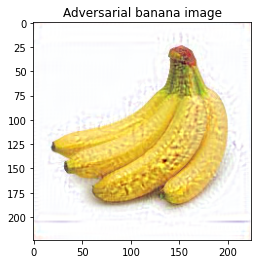

1/1 [==============================] - 1s 730ms/step
Predicted: [('n03825788', 'nipple', 0.6501887), ('n07753592', 'banana', 0.074898124), ('n01930112', 'nematode', 0.0710959)]


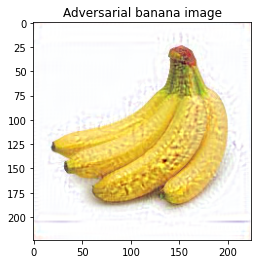

1/1 [==============================] - 1s 755ms/step
Predicted: [('n03825788', 'nipple', 0.6501887), ('n07753592', 'banana', 0.074898124), ('n01930112', 'nematode', 0.0710959)]


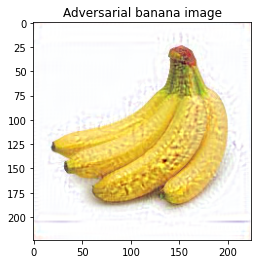

1/1 [==============================] - 1s 734ms/step
Predicted: [('n03825788', 'nipple', 0.6501887), ('n07753592', 'banana', 0.074898124), ('n01930112', 'nematode', 0.0710959)]


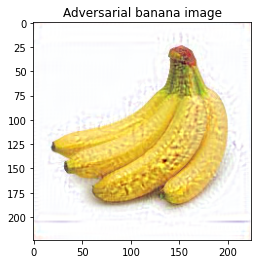

1/1 [==============================] - 1s 729ms/step
Predicted: [('n03825788', 'nipple', 0.6501887), ('n07753592', 'banana', 0.074898124), ('n01930112', 'nematode', 0.0710959)]


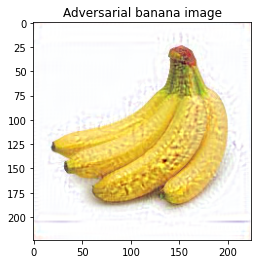

1/1 [==============================] - 1s 739ms/step
Predicted: [('n03825788', 'nipple', 0.6501887), ('n07753592', 'banana', 0.074898124), ('n01930112', 'nematode', 0.0710959)]


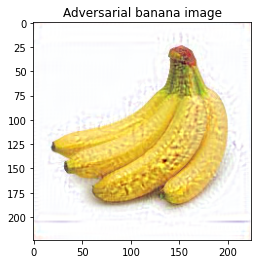

1/1 [==============================] - 1s 732ms/step
Predicted: [('n03825788', 'nipple', 0.6501887), ('n07753592', 'banana', 0.074898124), ('n01930112', 'nematode', 0.0710959)]


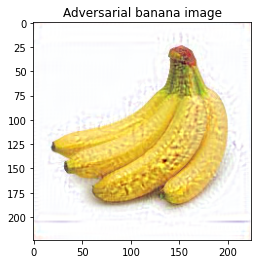

1/1 [==============================] - 1s 1s/step
Predicted: [('n03825788', 'nipple', 0.6501887), ('n07753592', 'banana', 0.074898124), ('n01930112', 'nematode', 0.0710959)]


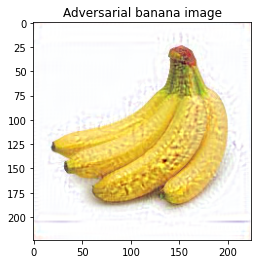

1/1 [==============================] - 1s 1s/step
Predicted: [('n03825788', 'nipple', 0.6501887), ('n07753592', 'banana', 0.074898124), ('n01930112', 'nematode', 0.0710959)]


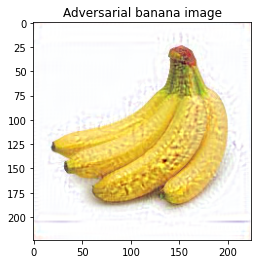

1/1 [==============================] - 1s 1s/step
Predicted: [('n03825788', 'nipple', 0.6501887), ('n07753592', 'banana', 0.074898124), ('n01930112', 'nematode', 0.0710959)]


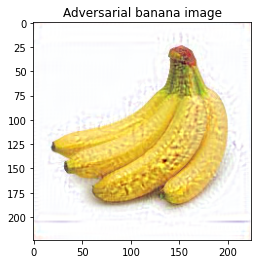

1/1 [==============================] - 1s 731ms/step
Predicted: [('n03825788', 'nipple', 0.6501887), ('n07753592', 'banana', 0.074898124), ('n01930112', 'nematode', 0.0710959)]


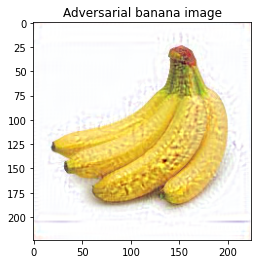

In [ ]:
for sample in raw_advs:
  preds = model.predict(sample)
  print('Predicted:', decode_predictions(preds, top=3)[0])
  plt.figure()
  plt.imshow(sample[0]/ 255)
  plt.title('Adversarial banana image')
  plt.show()

#ClippingAwareAdditiveUniformNoiseAttack

In [ ]:
from foolbox.attacks import L2ClippingAwareAdditiveUniformNoiseAttack
# apply the attack
attack = L2ClippingAwareAdditiveUniformNoiseAttack()


#так как преобразования к изображению применяются внутри модели foolbox, еще раз поместим его в переменную х
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
banana_image, banana_label = tf.convert_to_tensor(x), tf.convert_to_tensor(tf.cast([954], tf.int64))

#Заданим значения допустимых возмущений
epsilons = [0.0, 0.001, 0.01, 0.03, 0.1, 0.3, 0.5, 1.0, 2.0, 5.0, 10.0]

raw_advs, clipped_advs, success = attack(fmodel, banana_image, banana_label, epsilons=epsilons)


1/1 [==============================] - 1s 734ms/step
Predicted: [('n03825788', 'nipple', 0.5458824), ('n07753592', 'banana', 0.15353303), ('n03786901', 'mortar', 0.07084635)]


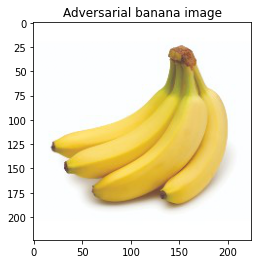

1/1 [==============================] - 1s 727ms/step
Predicted: [('n03825788', 'nipple', 0.5458824), ('n07753592', 'banana', 0.15353303), ('n03786901', 'mortar', 0.07084635)]


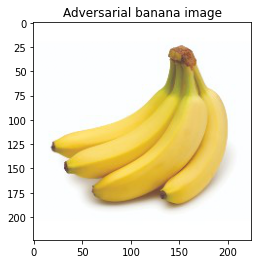

1/1 [==============================] - 1s 727ms/step
Predicted: [('n03825788', 'nipple', 0.5458824), ('n07753592', 'banana', 0.15353303), ('n03786901', 'mortar', 0.07084635)]


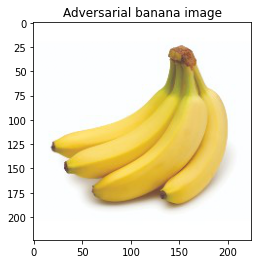

1/1 [==============================] - 1s 725ms/step
Predicted: [('n03825788', 'nipple', 0.5458824), ('n07753592', 'banana', 0.15353303), ('n03786901', 'mortar', 0.07084635)]


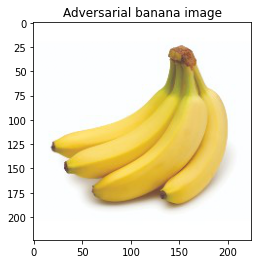

1/1 [==============================] - 1s 729ms/step
Predicted: [('n03825788', 'nipple', 0.5458801), ('n07753592', 'banana', 0.15353413), ('n03786901', 'mortar', 0.0708474)]


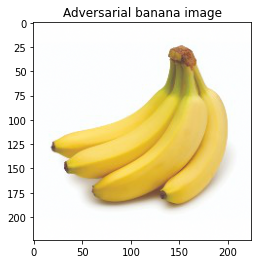

1/1 [==============================] - 1s 734ms/step
Predicted: [('n03825788', 'nipple', 0.545877), ('n07753592', 'banana', 0.15353589), ('n03786901', 'mortar', 0.07084828)]


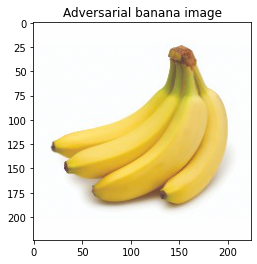

1/1 [==============================] - 1s 736ms/step
Predicted: [('n03825788', 'nipple', 0.5458645), ('n07753592', 'banana', 0.15354058), ('n03786901', 'mortar', 0.07085227)]


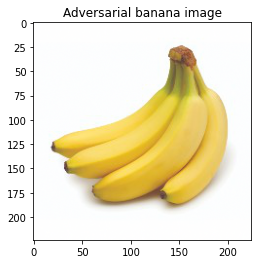

1/1 [==============================] - 1s 739ms/step
Predicted: [('n03825788', 'nipple', 0.5458931), ('n07753592', 'banana', 0.15351333), ('n03786901', 'mortar', 0.07084557)]


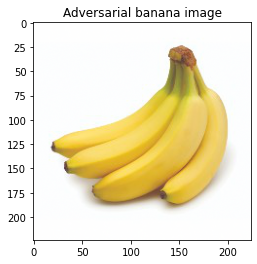

1/1 [==============================] - 1s 746ms/step
Predicted: [('n03825788', 'nipple', 0.5458433), ('n07753592', 'banana', 0.15353651), ('n03786901', 'mortar', 0.0708508)]


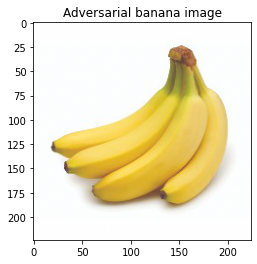

1/1 [==============================] - 1s 727ms/step
Predicted: [('n03825788', 'nipple', 0.54587674), ('n07753592', 'banana', 0.15354006), ('n03786901', 'mortar', 0.070852034)]


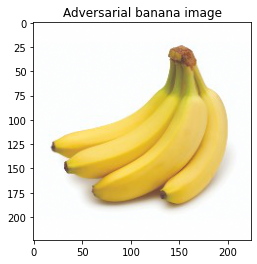

1/1 [==============================] - 1s 744ms/step
Predicted: [('n03825788', 'nipple', 0.54561526), ('n07753592', 'banana', 0.15366438), ('n03786901', 'mortar', 0.07094707)]


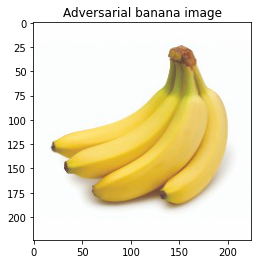

In [ ]:
for sample in raw_advs:
  preds = model.predict(sample)
  print('Predicted:', decode_predictions(preds, top=3)[0])
  plt.figure()
  plt.imshow(sample[0]/ 255)
  plt.title('Adversarial banana image')
  plt.show()

# InversionAttack

In [ ]:
from foolbox.attacks import InversionAttack
from foolbox.distances import Distance, LpDistance
# apply the attack
d = LpDistance(1)
attack = InversionAttack(distance = d)

#так как преобразования к изображению применяются внутри модели foolbox, еще раз поместим его в переменную х
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
banana_image, banana_label = tf.convert_to_tensor(x), tf.convert_to_tensor(tf.cast([954], tf.int64))

#Заданим значения допустимых возмущений
epsilons = [0.0, 0.001, 0.01, 0.03, 0.1, 0.3, 0.5, 1.0, 2.0, 5.0, 10.0]

raw_advs, clipped_advs, success = attack(fmodel, banana_image, banana_label, epsilons=epsilons)


1/1 [==============================] - 1s 742ms/step
Predicted: [('n01943899', 'conch', 0.55873525), ('n01833805', 'hummingbird', 0.122972175), ('n03637318', 'lampshade', 0.06502762)]


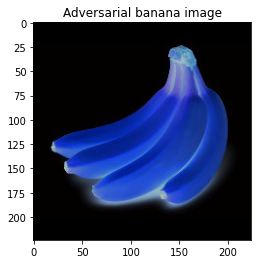

1/1 [==============================] - 1s 736ms/step
Predicted: [('n01943899', 'conch', 0.55873525), ('n01833805', 'hummingbird', 0.122972175), ('n03637318', 'lampshade', 0.06502762)]


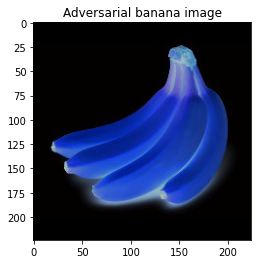

1/1 [==============================] - 1s 740ms/step
Predicted: [('n01943899', 'conch', 0.55873525), ('n01833805', 'hummingbird', 0.122972175), ('n03637318', 'lampshade', 0.06502762)]


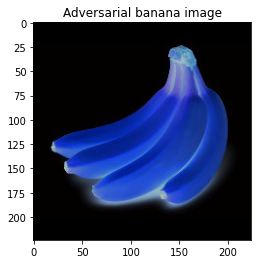

1/1 [==============================] - 1s 747ms/step
Predicted: [('n01943899', 'conch', 0.55873525), ('n01833805', 'hummingbird', 0.122972175), ('n03637318', 'lampshade', 0.06502762)]


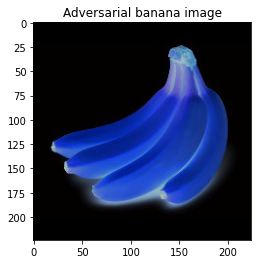

1/1 [==============================] - 1s 734ms/step
Predicted: [('n01943899', 'conch', 0.55873525), ('n01833805', 'hummingbird', 0.122972175), ('n03637318', 'lampshade', 0.06502762)]


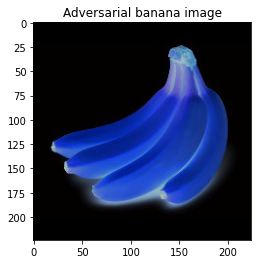

1/1 [==============================] - 1s 742ms/step
Predicted: [('n01943899', 'conch', 0.55873525), ('n01833805', 'hummingbird', 0.122972175), ('n03637318', 'lampshade', 0.06502762)]


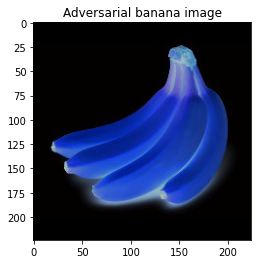

1/1 [==============================] - 1s 729ms/step
Predicted: [('n01943899', 'conch', 0.55873525), ('n01833805', 'hummingbird', 0.122972175), ('n03637318', 'lampshade', 0.06502762)]


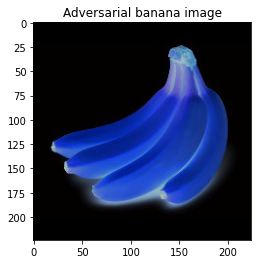

1/1 [==============================] - 1s 744ms/step
Predicted: [('n01943899', 'conch', 0.55873525), ('n01833805', 'hummingbird', 0.122972175), ('n03637318', 'lampshade', 0.06502762)]


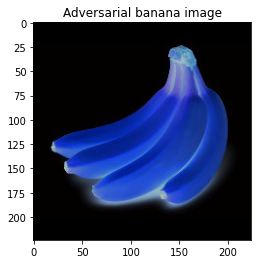

1/1 [==============================] - 1s 740ms/step
Predicted: [('n01943899', 'conch', 0.55873525), ('n01833805', 'hummingbird', 0.122972175), ('n03637318', 'lampshade', 0.06502762)]


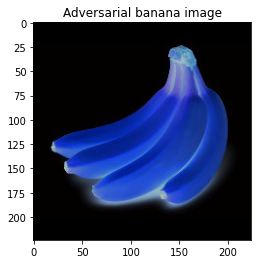

1/1 [==============================] - 1s 761ms/step
Predicted: [('n01943899', 'conch', 0.55873525), ('n01833805', 'hummingbird', 0.122972175), ('n03637318', 'lampshade', 0.06502762)]


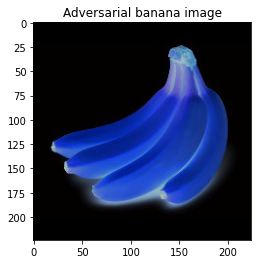

1/1 [==============================] - 1s 740ms/step
Predicted: [('n01943899', 'conch', 0.55873525), ('n01833805', 'hummingbird', 0.122972175), ('n03637318', 'lampshade', 0.06502762)]


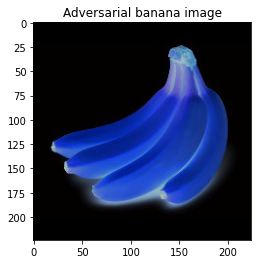

In [ ]:
for sample in raw_advs:
  preds = model.predict(sample)
  print('Predicted:', decode_predictions(preds, top=3)[0])
  plt.figure()
  plt.imshow(sample[0]/ 255)
  plt.title('Adversarial banana image')
  plt.show()